# Torsional buckling of ring- and stringer-stiffened cylinders: Moore and Wescoat (1944), Table II

Moore and Wescoat [1] tested in torsion five 24S-T cylinders of mean diameter $D = 30.08$ in,
stiffened by $1/2 \times 1/2$ in solid rings inside the skin and by 8 or 16 channel stringers
outside it (specimens 19, 14, 20, 15 and 21). Their Table II (p. 26) gives, for each size of
panel, the mean observed shear-buckling stress and the values computed with four theories; the
panels buckled one size after the other, the first buckling of each specimen being the panel of
lowest stress.

This notebook computes the first buckling stress of the perfect cylinders with
`panels.multidomain.MultiDomain`. The rings are modelled as in the notebook
`moore1944_ring_cylinders` (annular webs on the inner surface of the skin); each stringer is a
strip of the skin with the base of the channel as a second layer, two webs and two lips, flat
plates. The same cases are modelled with BFSC finite elements in the notebook
`moore1944_stiffened_cylinders` of the bfsccylinder package; its values are compared in Section 5.

Lengths in in, forces in lbf, stresses in psi, torques in ft-lb as in [1].

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt

import panels
import moore1944_utils as mu
from moore1944_utils import print_table, rel

%matplotlib inline
print('panels', panels.__version__)
SPECS = ['19', '14', '20', '15', '21']

panels 0.15.0


## 1. Data

From [1] ("p." is the printed page, the PDF page is two more); the material, the diameter, the
bulkheads and the rings are those of the notebook `moore1944_ring_cylinders`.

| quantity | value | source |
|---|---|---|
| sheet thickness | 0.020 in (19, 14, 20), 0.0195 in (15), 0.0205 in (21) | Table II, Fig. 11 |
| stringers | 8 (11.81 in apart) or 16 (5.90 in apart), equally spaced, one on the seam | Table II, Fig. 1 |
| stringer section | channel of 0.032 in 24S-T sheet, base 1/2 in wide on the skin, depth 0.64 in, overall width 1.12 in with the curled lips, bend radius 1/8 in; $A = 0.072$ in², $I_{XX} = 0.00375$ in⁴, $I_{YY} = 0.0063$ in⁴ | Fig. 1, Fig. 30 |
| attachment | one row of 1/8 in A17S-T rivets through the base | Fig. 1 (pitch not legible) |
| ring stations | Fig. 11, from the centres of the end bulkheads, 35 5/8 in apart | Fig. 11 |
| first buckling: panel and stress | Table II, lowest stress of each specimen | p. 26 |
| stress and torque | $\tau = 0.422\,T$ ($t = 0.020$ in), $0.433\,T$ (0.0195 in), $0.412\,T$ (0.0205 in); $T = \tau \pi D^2 t/24$ | Fig. 11, note 2; p. 7 |

The computed columns of Table II are, for the same panels: ANC-5 [2], Kromm [3], Ebner [4] and
Donnell [5], the last one "for cylinders having lengths equal to ring-stiffener spacings but without
longitudinals". For specimen 15, Table II prints the Kromm and Ebner values (2880 and 3170 psi) only
on the line of the 9.00 in panels, which buckled after the 8.81 in end panels (Table III gives the
same ratios on that line); they are not used for the first buckling.

In [2]:
rows = []
for s in SPECS:
    d = mu.SPECIMENS[s]
    rows.append([s, d['t'], d['nstr'], ' | '.join('%g' % b for b in d['bays']), d['panel'],
                 d['obs']] + ['-' if c is None else c for c in d['computed']])
print_table(rows, ['spec', 't (in)', 'stringers', 'bays (in)', 'first panel (in)',
                   'observed (psi)', 'ANC-5', 'Kromm', 'Ebner', 'Donnell'])

spec  t (in)  stringers                              bays (in)  first panel (in)  observed (psi)  ANC-5  Kromm  Ebner  Donnell
----  ------  ---------  -------------------------------------  ----------------  --------------  -----  -----  -----  -------
  19    0.02          8          4.3125 | 13.5 | 13.5 | 4.3125     13.50 x 11.81            2110   1620   1810   2320     2210
  14    0.02          8    4.3125 | 4.5 | 9 | 9 | 4.5 | 4.3125      9.00 x 11.81            2950   1750   2700   2960     2770
  20    0.02         16          4.3125 | 13.5 | 13.5 | 4.3125      13.50 x 5.90            2870   2070   2600   2570     2210
  15  0.0195         16                8.8125 | 9 | 9 | 8.8125       8.81 x 5.90            3370   2110      -      -     2680
  21  0.0205         16  2.0625 | 6.75 | 9 | 9 | 6.75 | 2.0625       9.00 x 5.90            4120   2240      -      -     2910


## 2. The model

**Skin and rings** as in `moore1944_ring_cylinders`: curved domains `cylshell_clpt_sanders`, one
bay per ring spacing along the axis, rings as webs of `annular_clpt_donnell` domains of $1/2 \times
1/2$ in connected to the inner surface of the skin with `'BFxcte'` and `face='lower'`; ends $u = v =
w = 0$ with $w_{,x}$ free (hinged). Along the circumference each stringer pitch is split into the
strip under the base of the stringer and the bay between two stringers.

**Stringers.** The channel is assembled from flat strips, as the Z stringers of
`panels.multidomain.create_cylinder_z_stiffened` (not used here, since the channel has two webs):

- the base is a second layer, 0.032 in thick, of the laminate of the strip under it, on the outer
  face of the skin; the laminate has the offset $+t_z/2$ so that the reference surface of the strip
  remains the middle surface of the skin, shared with the bays (continuous bond; the rivet line of
  [1] is not represented, its pitch being a later sensitivity);
- each web is a flat plate `plate_clpt_donnell` standing outside on an edge of the strip, connected
  with `'BFycte'` at the reference surface of the strip, from the middle surface of the skin to the
  middle plane of the lip, $H_w = t/2 + 0.64 - t_z/2$;
- each lip is a flat plate connected to the free edge of its web with `'BFycte'` and bent away from
  the channel; the curls of [1] are not represented.

The strip spans the middle planes of the two webs, $b_s = 1/2 - t_z$ (the 1/2 in of Fig. 1 is
read as the outer width of the base). The developed length of the curled lips is not given, and the
lip width $b_l$ is chosen so that the five plates have the area of the section measured by weighing,
$A = 0.072$ in² ([1] p. 8, Fig. 30). The webs and lips are split at the ring stations as the skin,
and are held by the bulkheads at the ends as the skin.

**Load.** The constant shear flow $N_{xy} = 1$ lbf/in is given to the skin and to the strips; the
rings and the plates of the stringers carry no stress in the membrane state of a perfect cylinder in
torsion. The critical shear flow is the lowest load multiplier of the linear buckling problem
reduced with the null space of the connections, as in `moore1944_ring_cylinders`, and $\tau_{cr} =
\lambda/t$ with $t$ the skin thickness.

In [3]:
sec = mu.stringer_section(0.020)
rows = [['A (in^2)', '%.4f' % sec['A'], 0.072, '%+.1f' % rel(sec['A'], 0.072)],
        ['I_XX (in^4), axis parallel to the skin', '%.5f' % sec['Ixx'], 0.00375,
         '%+.1f' % rel(sec['Ixx'], 0.00375)],
        ['I_YY (in^4), axis normal to the skin', '%.5f' % sec['Iyy'], 0.0063,
         '%+.1f' % rel(sec['Iyy'], 0.0063)]]
print('strip b_s = %.3f in, web H_w = %.3f in, lip b_l = %.3f in'
      % (sec['bs'], sec['Hw'], sec['bl']))
print_table(rows, ['section without the skin', 'model', 'Fig. 30 [1]', 'diff %'])

strip b_s = 0.468 in, web H_w = 0.634 in, lip b_l = 0.257 in
              section without the skin    model  Fig. 30 [1]  diff %
--------------------------------------  -------  -----------  ------
                              A (in^2)   0.0714        0.072    -0.9
I_XX (in^4), axis parallel to the skin  0.00420      0.00375   +12.1
  I_YY (in^4), axis normal to the skin  0.00472       0.0063   -25.2


The flat lips give an $I_{XX}$ 12 % above and an $I_{YY}$ 25 % below the values of Fig. 30, which
were measured in bending tests ([1] p. 8): the curls, not represented, put part of the lips back
towards the base and out to the overall width of 1.12 in. The stringers are not loaded before buckling, so their inertias enter only through
the support they give to the skin.

**Runs.** The analyses are run on a cluster node by `moore1944_runs.py` (stage 2), which writes
`results/moore1944_stage2.json`. Meshes (terms per inch, at least 6 along the axis per bay and 8
across a bay, at most 30):

| mesh | across a bay between stringers | along the axis | across strip, web, lip |
|---|---|---|---|
| A | 1.5 | 0.8 | 4, 6, 4 |
| B | 2.0 | 1.0 | 4, 6, 4 |
| C | 2.5 | 1.2 | 5, 8, 5 |

In [4]:
with open('results/moore1944_stage2.json') as f:
    RES = json.load(f)
errors = [r for r in RES if 'error' in r]
print('%d cases, %d errors' % (len(RES), len(errors)))
for r in errors:
    print(r['case'], r['spec'], r['error'])
res = {(r['case'], r['spec']): r for r in RES if 'error' not in r}

45 cases, 0 errors


## 3. Convergence

In [5]:
rows = []
for s in SPECS:
    prev = None
    for mesh in 'ABC':
        r = res.get(('mesh ' + mesh, s))
        if r is None:
            rows.append([s, mesh, '', '', 'not run', '', '', ''])
            continue
        ch = '' if prev is None else '%+.2f' % rel(r['tau'], prev)
        rows.append([s, mesh, r['domains'], r['size_r'], '%.1f' % r['tau'], ch, r['waves'],
                     '%.0f' % r['seconds']])
        prev = r['tau']
print_table(rows, ['spec', 'mesh', 'domains', 'independent constants', 'tau_cr (psi)',
                   'change %', 'n', 's'])

spec  mesh  domains  independent constants  tau_cr (psi)  change %   n     s
----  ----  -------  ---------------------  ------------  --------  --  ----
  19     A      240                  30288        2581.4            17   559
  19     B      240                  42240        2579.5     -0.07  17   883
  19     C      240                  59520        2579.3     -0.01  17  1513
  14     A      368                  35440        3135.2            20   172
  14     B      368                  47056        3054.4     -2.58  20   489
  14     C      368                  65488        3049.7     -0.16  20   793
  20     A      480                  41568        4336.8            17  1136
  20     B      480                  55680        3944.0     -9.06  18   623
  20     C      480                  82752        3940.0     -0.10  18  1147
  15     A      480                  34656        4708.8            17   110
  15     B      480                  50496        4071.8    -13.53  19   485

## 4. Sensitivity

Mesh B, one change at a time: clamped ends; $u$ free at the loaded end $x = L$ ($u = 0$ at $x = 0$); rigid ring supports; the
Donnell kinematics in the skin; no stringers (the ring-stiffened cylinder, 16 sectors of 14
terms); lips 0.31 in wide from the outer face of the web (the geometric width $(1.12 - 0.5)/2$ of
Fig. 30, area 0.0756 in²).

In [6]:
SENS = ['clamped', 'u free', 'rigid rings', 'Donnell skin', 'no stringers', 'lips 0.31 in']
rows = []
for s in SPECS:
    base = res[('mesh B', s)]['tau']
    row = [s, '%.1f' % base]
    for name in SENS:
        r = res.get((name, s))
        row += ['%.1f (%+.1f %%)' % (r['tau'], rel(r['tau'], base)) if r else 'n/a']
    rows.append(row)
print_table(rows, ['spec', 'mesh B'] + SENS)

spec  mesh B          clamped           u free      rigid rings     Donnell skin      no stringers     lips 0.31 in
----  ------  ---------------  ---------------  ---------------  ---------------  ----------------  ---------------
  19  2579.5  2579.5 (+0.0 %)  2579.4 (-0.0 %)  2555.0 (-0.9 %)  2579.8 (+0.0 %)  2207.4 (-14.4 %)  2579.8 (+0.0 %)
  14  3054.4  3054.4 (+0.0 %)  3054.4 (-0.0 %)  3003.2 (-1.7 %)  3054.5 (+0.0 %)  2744.0 (-10.2 %)  3054.6 (+0.0 %)
  20  3944.0  3944.0 (+0.0 %)  3943.9 (-0.0 %)  3934.6 (-0.2 %)  3942.6 (-0.0 %)  2207.4 (-44.0 %)  3946.8 (+0.1 %)
  15  4071.8  4071.9 (+0.0 %)  4038.7 (-0.8 %)  4044.7 (-0.7 %)  4070.7 (-0.0 %)  2650.4 (-34.9 %)  4072.6 (+0.0 %)
  21  4370.7  4370.7 (+0.0 %)  4370.7 (-0.0 %)  4343.5 (-0.6 %)  4369.6 (-0.0 %)  2827.6 (-35.3 %)  4371.6 (+0.0 %)


## 5. Comparison with Table II and with bfsccylinder

$\tau_{FE}$ is the first buckling stress of the perfect cylinder, finest mesh, hinged ends. The
bfsccylinder values are those of the notebook `moore1944_stiffened_cylinders` of that package (BFSC
cylinder elements of Sanders-type kinematics, the channel of BFSC plates on a two-layer strip,
lips 0.283 in, rings as bands of skin elements with the laminate skin + bar, one stringer pitch
with Bloch conditions): 2619, 3134, 3970, 4118 and 4422 psi for specimens 19, 14, 20, 15 and 21.

In [7]:
BFSC = {'19': 2619, '14': 3134, '20': 3970, '15': 4118, '21': 4422}
rows = []
for s in SPECS:
    d = mu.SPECIMENS[s]
    r = res.get(('mesh C', s)) or res.get(('mesh B', s))
    comp = ['-' if c is None else '%+.0f' % rel(r['tau'], c) for c in d['computed']]
    rows.append([s, d['panel'], r['kwargs'].get('n_per_in'), r['waves'], '%.0f' % r['tau'],
                 '%.0f' % r['T'], d['obs'], '%.0f' % mu.torque_ftlb(d['obs'], d['t']),
                 '%+.1f' % rel(r['tau'], d['obs'])] + comp
                + [BFSC[s], '%+.1f' % rel(r['tau'], BFSC[s])])
print_table(rows, ['spec', 'first panel', 'n/in', 'n', 'tau_FE (psi)', 'T_FE (ft-lb)',
                   'observed (psi)', 'observed (ft-lb)', 'FE vs obs %', 'vs ANC-5 %',
                   'vs Kromm %', 'vs Ebner %', 'vs Donnell %', 'bfsccylinder',
                   'panels vs bfsc %'])

spec    first panel  n/in   n  tau_FE (psi)  T_FE (ft-lb)  observed (psi)  observed (ft-lb)  FE vs obs %  vs ANC-5 %  vs Kromm %  vs Ebner %  vs Donnell %  bfsccylinder  panels vs bfsc %
----  -------------  ----  --  ------------  ------------  --------------  ----------------  -----------  ----------  ----------  ----------  ------------  ------------  ----------------
  19  13.50 x 11.81   2.5  17          2579          6110            2110              4998        +22.2         +59         +43         +11           +17          2619              -1.5
  14   9.00 x 11.81   2.5  20          3050          7224            2950              6988         +3.4         +74         +13          +3           +10          3134              -2.7
  20   13.50 x 5.90   2.5  18          3940          9333            2870              6798        +37.3         +90         +52         +53           +78          3970              -0.8
  15    8.81 x 5.90   2.5  19          4060          9378        

## 6. Buckling modes

Radial displacement $w$ of the first mode on the unrolled skin (finest mesh, arbitrary scale);
dashed lines: rings; dotted lines: stringers.

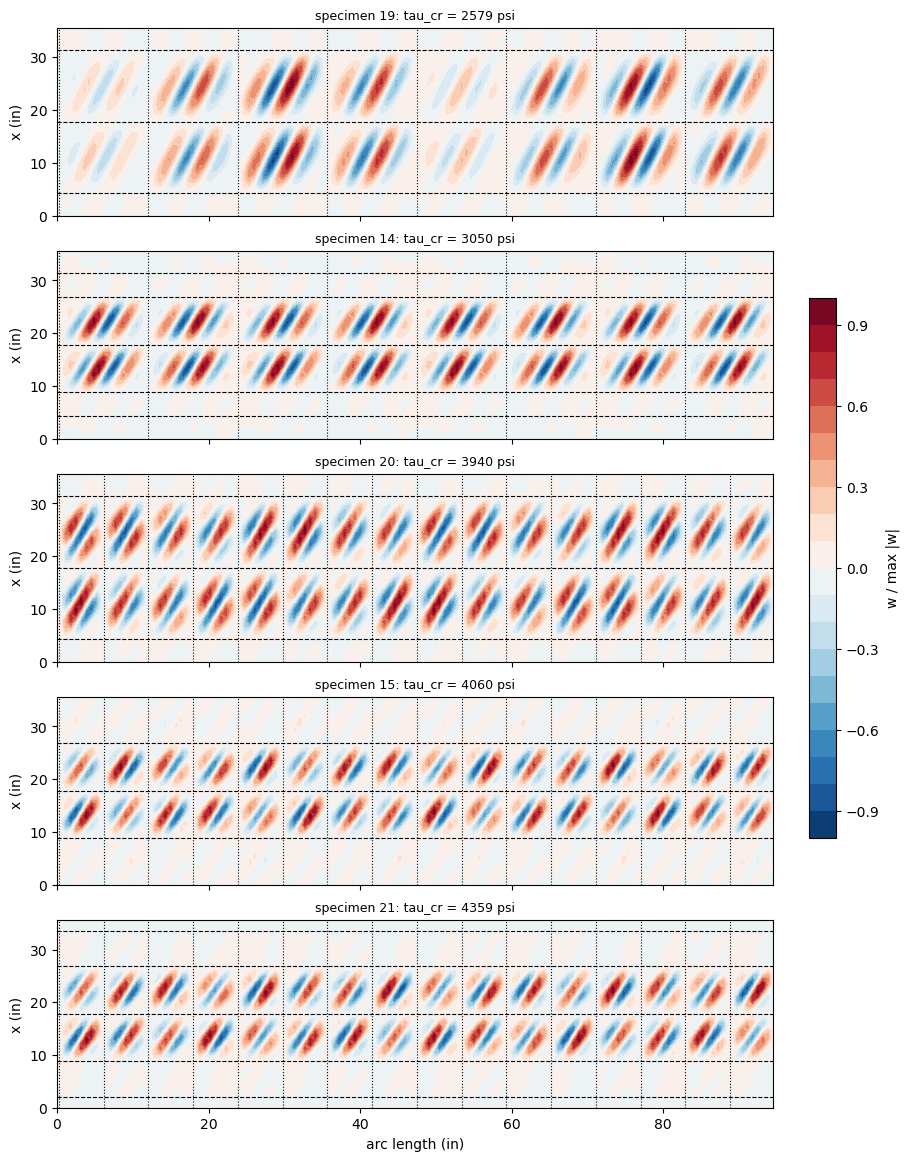

In [8]:
fig, axes = plt.subplots(len(SPECS), 1, figsize=(9, 2.3*len(SPECS)), sharex=True,
                         constrained_layout=True)
for ax, s in zip(axes, SPECS):
    r = res.get(('mesh C', s)) or res.get(('mesh B', s))
    mode = r.get('mode')
    if mode is None:
        continue
    wmax = max(np.abs(np.array(W)).max() for W in mode['W'])
    for X, S, W in zip(mode['X'], mode['S'], mode['W']):
        cs = ax.contourf(np.array(S), np.array(X), np.array(W)/wmax,
                         levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    x = 0.
    for b in mu.SPECIMENS[s]['bays'][:-1]:
        x += b
        ax.axhline(x, color='k', ls='--', lw=0.8)
    ns = mu.SPECIMENS[s]['nstr']
    for k in range(ns):
        ax.axvline(k*2*np.pi*mu.R/ns + 0.234, color='k', ls=':', lw=0.8)
    ax.set_ylabel('x (in)')
    ax.set_title('specimen %s: tau_cr = %.0f psi' % (s, r['tau']), fontsize=9)
axes[-1].set_xlabel('arc length (in)')
fig.colorbar(cs, ax=axes, shrink=0.5, label='w / max |w|')
plt.show()

## 7. Discussion

- **Convergence.** The last refinement changes $\tau_{cr}$ by 0.3 % or less (Section 3). The
  16-stringer cylinders need about two terms per inch across the 5.4 in bays: mesh A, with 8
  terms, is 10 to 16 % high for them.
- **Effect of the stringers.** Without stringers (Section 4) the model gives 2207 psi for
  specimens 19 and 20 (the rings of specimen 18), 2744 psi for 14 (those of 13A), 2650 and 2828 psi
  for 15 and 21; these are within 0.1 to 2.8 % of Donnell's column of Table II, computed by Moore
  and Wescoat for an unstiffened cylinder of the bay length. The 8 stringers raise the first
  buckling stress by 11 to 17 %, the 16 stringers by 53 to 79 %.
- **Computed columns of Table II.** For the 8-stringer specimens Ebner's values are the nearest to
  the model (11 % and 3 % below it); for the 16-stringer specimens the model is about 50 to 95 %
  above every column. Those formulas are for a curved panel between the stiffeners with assumed
  edge conditions ([1] appendix, pp. 21-23); the model represents the stringers and the rings with
  their stiffnesses.
- **Test values.** The observed first buckling stresses are 3.4 % (14) to 37 % (20) below those of
  the perfect cylinders. For the specimens other than 14 they come from one test (Fig. 11, note 1);
  [1] reports for the ring-only cylinders minima of 83 to 98 % of the maxima of repeated tests
  (p. 8), and the panels of the stiffened cylinders buckled one after the other, with the torque
  falling at each buckling (p. 5). For specimen 15 the first mode of the model is in the 9 in
  intermediate panels, whereas the 8.81 in end panels buckled first in the test, at 3370 psi
  against 3590 psi for the 9 in panels (Table II); for the other specimens the mode is in the
  panels that buckled first (Section 6).
- **Sensitivities.** The end conditions change $\tau_{cr}$ by 0.8 % or less, rigid ring supports
  lower it by 0.2 to 1.7 %, the Donnell kinematics of the skin by 0.04 % or less, and the lip width
  of the flat geometric lips (0.326 in instead of 0.257 in) by 0.07 % or less.
- **bfsccylinder.** The BFSC model gives 0.8 % (specimen 20) to 2.8 % (14) more; it has flat lips
  of 0.283 in and rings as bands of skin elements, whose Kirchhoff torsional stiffness restrains the
  rotation of the skin more than the annular webs (see the notebook `moore1944_ring_cylinders`,
  where the two models differ by 0.1 to 3.2 %).
- **Not represented.** The rivets (one row through the base, pitch not legible in Fig. 1; a
  rivet-pitch sensitivity with discrete connections is left for later), the curls of the lips and
  the bends of the channel, the seam stringer joint, the pins of the rings and the initial
  imperfections. The webs are connected to the strip at the middle surface of the skin, as the
  connection `'BFycte'` has no key for a face of its base; the overlap of the web with the skin and
  the base is 0.026 in.

## References

1. Moore, R. L., and Wescoat, C., "Torsion Tests of Stiffened Circular Cylinders", NACA ARR 4E31
   (Wartime Report W-89), 1944: Table II p. 26, Figs. 1, 11 and 30.
2. Anon., "Strength of Aircraft Elements", Army-Navy-Civil Committee on Aircraft Design Criteria
   (ANC-5), 1942 (as cited in [1]).
3. Kromm, A., "The Limit of Stability of a Curved Plate Strip under Shear and Axial Stresses", NACA
   TM 898, 1939 (as cited in [1]).
4. Ebner, H., "The Strength of Shell Bodies - Theory and Practice", NACA TM 838, 1937 (as cited in
   [1]).
5. Donnell, L. H., "Stability of Thin-Walled Tubes under Torsion", NACA Report 479, 1933 (as given in
   [1], p. 23).
6. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear
   buckling and vibration of stiffened composite panels with debonding defect", Composite
   Structures, 160, 2017, pp. 232-247, doi:10.1016/j.compstruct.2016.10.026.